<a href="https://colab.research.google.com/github/ManalZar/COURSE/blob/main/ABM_Misinformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Modelling Misinformation transmission and transformation using Agent-Based Models**
Younes Jeddi, Azeez Hamzat, and Ali Anesrif Supervised by Pr. James Winters\
Code By *Younes Jeddi*\
CICS302 - Final Project code

# Needs

In [ ]:
import pandas as pd
import numpy as np
from random import seed
from random import random
import editdistance
import copy
import seaborn as sns; sns.set()
import matplotlib.pyplot as plt
from IPython.display import set_matplotlib_formats
set_matplotlib_formats('svg', 'pdf')

# **Model 1: Sharing the misinformation**

## Hypothesis 1: The Vulnerability of agents staring the misinformation and the number of interactions will impact the spread of misinformation.

In [ ]:
def fakeSpread(N, interactions = 1000, F=1):
  agents = []
  seed(1)
  for i in range(N):
    e = random()
    agents.append(['A', e])
  #e is the vulnerabilty to misinformation

  #Choose a random agent to give him misinformation
  if F < N:
    for i in range(F):
      f = np.random.choice(range(N))
      agents[f][0] = 'F'
  else:
    print("Number of initial agents with fake news should be inferior to the total population")
    return None;

  df = pd.DataFrame(agents)

  data = [[1, df[0].value_counts()['A']/N]]
  output = pd.DataFrame(data, columns = ['tmax', 'p'])
  #output

  for t in range(interactions):
    j = np.random.choice(range(N))
    k = np.random.choice(range(N))

    if j != k:
      if agents[j][0] != agents[k][0]:
        if agents[j][0] == 'F':
          if agents[j][1] >= agents[k][1]:
            agents[k][0] = 'F'
        elif agents[k][0] == 'F':
          if agents[k][1] >= agents[j][1]:
            agents[j][0] = 'F'
      df = pd.DataFrame(agents)
      exists = 'A' in df[0].unique()
      if exists:
        s = df[0].value_counts()['A']
      else:
        s = 0
      o = {'tmax': t, 'p': s/N}
      output = output.append(o, ignore_index = True)
  return output;

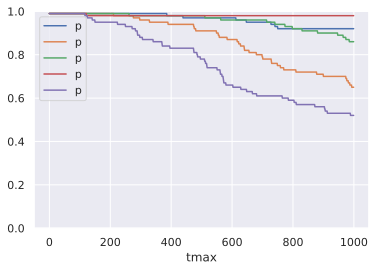

In [ ]:
for r in range(5):
  output = fakeSpread(100, 1000, 1)
  ax = plt.gca()

  output.plot(kind='line',x='tmax',y='p',ax=ax)
  plt.ylim(0, 1)

To check the impact of the number of interactions on the spread we lowered the interactions to 500.

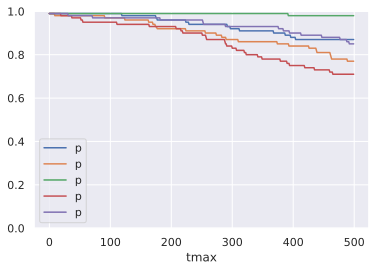

In [ ]:
for r in range(5):
  output = fakeSpread(100, 500, 1)
  ax = plt.gca()

  output.plot(kind='line',x='tmax',y='p',ax=ax)
  plt.ylim(0, 1)

## Hypothesis 2: When agents will start correcting each other the rate of misinformation will decrease.

In [ ]:
def fakeSpread2(N, interactions, F=1):
  agents = []
  seed(1)
  for i in range(N):
    e = random()
    agents.append(['A', e])
  #e is the sensitivity to misinformation

  #Choose a random agent to give him fake news
  if F < N:
    for i in range(F):
      f = np.random.choice(range(N))
      agents[f][0] = 'F'
  else:
    print("Number of initial agents with fake news should be inferior to the total population")
    return None;

  df = pd.DataFrame(agents)

  data = [[1, df[0].value_counts()['A']/N]]
  output = pd.DataFrame(data, columns = ['tmax', 'p'])
  #output


  for t in range(interactions):
    j = np.random.choice(range(N))
    k = np.random.choice(range(N))

    if j != k:
      if agents[j][0] != agents[k][0]:
        if agents[j][1] >= agents[k][1]:
          agents[k][0] = agents[j][0]
        else:
          agents[j][0] = agents[k][0]
      df = pd.DataFrame(agents)
      exists = 'A' in df[0].unique()
      if exists:
        s = df[0].value_counts()['A']
      else:
        s = 0
      o = {'tmax': t, 'p': s/N}
      output = output.append(o, ignore_index = True)
  return output;

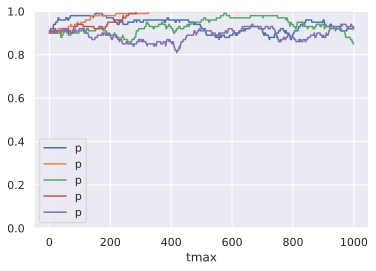

In [ ]:
for r in range(5):
  output = fakeSpread2(100, 1000, 10)
  ax = plt.gca()

  output.plot(kind='line',x='tmax',y='p',ax=ax)
  plt.ylim(0, 1)

# **Model 2: From Information to Misinformation**

## Functions

In [ ]:
import editdistance as ld
import statistics

def modification(sol):
	sol = np.asarray([i for i in sol])
	s_locs = [i for i in range(len(sol))]
	val_loc = np.random.choice(s_locs)
	value = sol[val_loc]
	if value == '0':
		new_sol = np.delete(sol,val_loc,0)
		new_sol = np.insert(new_sol,val_loc,'1')
	elif value == '1':
		new_sol = np.delete(sol,val_loc,0)
		new_sol = np.insert(new_sol,val_loc,'0')
	return ''.join(list(new_sol))

def insertion(sol):
	sol = np.asarray([i for i in sol])
	s_locs = [i for i in range(len(sol)+1)]
	val_loc = np.random.choice(s_locs)
	value = np.random.choice(np.asarray(['0','1']))
	new_sol = np.insert(sol,val_loc,value)
	return ''.join(list(new_sol))

def deletion(sol):
	sol = np.asarray([i for i in sol])
	if len(sol) > 2:
		s_locs = [i for i in range(len(sol))]
		val_loc = np.random.choice(s_locs)
		new_sol = np.delete(sol,val_loc,0)
	else:
		new_sol = sol
	return ''.join(list(new_sol))

#best
def local(sol,problem):
	local_pool = [modification(sol=sol),insertion(sol=sol),deletion(sol=sol)]
	optimal_sol = sorted(local_pool, key=lambda x: editdistance.eval(x,problem))[0]
	return optimal_sol

def optimization(current,problem): #REMEMBER TO REMOVE agent AND memory
	ag_loc = local(sol=current,problem=problem)
	sol_pool = [current,ag_loc]
	return sol_pool

# transmission
def sol_inherit(sol,e):
	if len(sol) > 2:
		in_sol = np.asarray([i for i in sol])
		#print(in_sol)
		err = np.random.choice([True,False],len(sol),p=[e,1.0-e])
		val_loc = [i for i,j in zip(range(0,len(sol)),list(err)) if j==True]
		new_sol = np.delete(in_sol,val_loc,0)
		return ''.join(list(new_sol))
	else:
		return sol

#test: sol_inherit(sol='01010111',e=0.05)

def cultural_transmission(inheritance,transmission,agent,agents,memory,error,problem):
	if inheritance == True:
		mem_update = inherit(agent=agent,memory=memory,e=error)
	else:
		transmission_type = np.random.choice(['biased','random'],1,p=[transmission,1-transmission])
		if transmission_type == 'random':
			mem_update = inherit(agent=random.choices(agents,k=1)[0],memory=memory,e=error)
		elif transmission_type == 'biased':
			selection = biased_transmission(agents=agents,memory=memory,problem=problem)
			mem_update = [sol_inherit(sol=selection,e=error)]
	return mem_update

def count_avg(agents, info):
	a = []
	for agent in agents:
		if agent[0] != '':
			a.append(ld.eval(info, agent[0]))
	#print(a)
	avg_val = statistics.mean(a)
	return round(avg_val, 2)

## Information transformation inside the population

In [ ]:
def fakeSpread_up(N, info, e, F = 1):
  agents = []
  seed(1)
  for i in range(N):
    e = round(random(), 2)
    agents.append(['', e])
  #e is the sensitivity to news: low e means you will highly believe the news

  #Choose a random agent to give him fake news
  if F < N:
    for i in range(F):
      f = np.random.choice(range(N))
      agents[f][0] = info
  else:
    print("Number of initial agents with fake news should be inferior to the total population")
    return None;
  # We will calculate the avg levenshtein distance inside the population at each time t
  # This will tell us how much the information transformed inside the population
  data =[[1, count_avg(agents, info)]]
  output = pd.DataFrame(data, columns = ['tmax', 'avg'])

  #Simulation
  for t in range(1000):
    j = np.random.choice(range(N))
    k = np.random.choice(range(N))
    if j != k:
        if agents[j][0] != agents[k][0]:
            if agents[j][1] >= agents[k][1] and agents[j][0] != '':
              agents[k][0] = sol_inherit(agents[j][0], e)
              ##
            elif agents[k][1] >= agents[j][1] and agents[k][0] != '':
              agents[j][0] = sol_inherit(agents[k][0], e)
    df = pd.DataFrame(agents)

    o = {'tmax': t, 'avg': count_avg(agents, info)}
    output = output.append(o, ignore_index = True)
    levd = []
    for y in range(len(agents)):
      levd.append(ld.eval(info, agents[y][0]))
    df['levd'] = levd
  return output;


Testing it for a long string

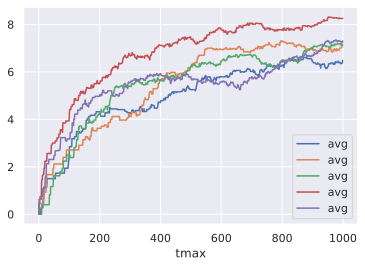

In [ ]:
for r in range(5):
  output = fakeSpread_up(100, '10110101010', 0.01, 10)
  ax = plt.gca()

  output.plot(kind='line',x='tmax',y='avg',ax=ax)
  #plt.ylim(0, 1)

Testing it for a short string

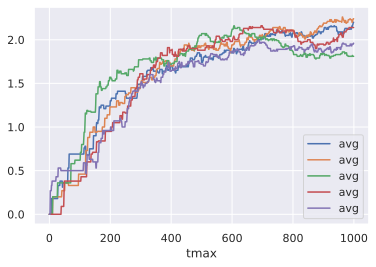

In [ ]:
for r in range(5):
  output = fakeSpread_up(100, '1010', 0.01, 10)
  ax = plt.gca()

  output.plot(kind='line',x='tmax',y='avg',ax=ax)
  #plt.ylim(0, 1)

## Information transformation + looking for the truth (Debunking)

In [ ]:
def fakeSpread_up2(N, info, e, F = 1):
  agents = []
  seed(1)
  for i in range(N):
    e = round(random(), 2)
    agents.append(['', e])
  #e is the sensitivity to news: low e means you will highly believe the news

  #Choose a random agent to give him fake news
  if F < N:
    for i in range(F):
      f = np.random.choice(range(N))
      agents[f][0] = info
  else:
    print("Number of initial agents with fake news should be inferior to the total population")
    return None;
  # We will calculate the avg levenshtein distance inside the population at each time t
  # This will tell us how much the information transformed inside the population
  data =[[1, count_avg(agents, info)]]
  output = pd.DataFrame(data, columns = ['tmax', 'avg'])

  #Simulation
  for t in range(1000):
    j = np.random.choice(range(N))
    k = np.random.choice(range(N))
    if j != k:
        if agents[j][0] != agents[k][0]:
            if agents[j][1] >= agents[k][1] and agents[j][0] != '':
              agents[k][0] = sol_inherit(agents[j][0], e)
              if agents [k][0] != '':
                agents[k][0] = local(agents[k][0], info)
              ##
            elif agents[k][1] >= agents[j][1] and agents[k][0] != '':
              agents[j][0] = sol_inherit(agents[k][0], e)
              if agents[j][0] != '':
                agents[j][0] = local(agents[j][0], info)
    df = pd.DataFrame(agents)

    o = {'tmax': t, 'avg': count_avg(agents, info)}
    output = output.append(o, ignore_index = True)
    levd = []
    for y in range(len(agents)):
      levd.append(ld.eval(info, agents[y][0]))
    df['levd'] = levd
  return output;


Testing it for a long string

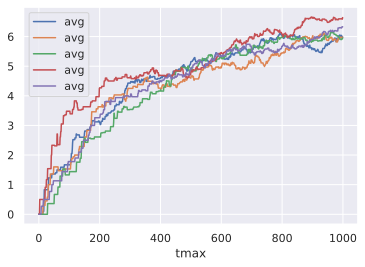

In [ ]:
for r in range(5):
  output = fakeSpread_up2(100, '10110101010', 0.01, 10)
  ax = plt.gca()

  output.plot(kind='line',x='tmax',y='avg',ax=ax)
  #plt.ylim(0, 1)

Testing it for a short string

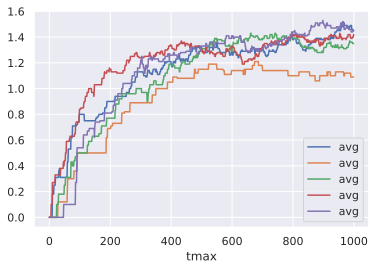

In [ ]:
for r in range(5):
  output = fakeSpread_up2(100, '1010', 0.01, 10)
  ax = plt.gca()

  output.plot(kind='line',x='tmax',y='avg',ax=ax)
  #plt.ylim(0, 1)

# **Draft (Not related to the report)**

In [ ]:
agent = ['A', 0.5]
N = 100

In [ ]:
agents = []

for i in range(N):
  education = (0.2, 0.5, 0.8)
  p = (0.3, 0.4, 0.3)
  e = np.random.choice(education, size=1, p=p)
  agents.append(['A', e[0]])
#e is the sensitivity to news: low e means you will highly believe the news

In [ ]:
df = pd.DataFrame(agents)

data = [[1, df[0].value_counts()['A']/N]]
output = pd.DataFrame(data, columns = ['tmax', 'p'])
output

,tmax,p
0,1,1.0


### **random sensitivity**

In [ ]:
def fakeSpread(N):
  agents = []
  for i in range(N):
    education = (0.2, 0.5, 0.8)
    p = (0.3, 0.4, 0.3)
    e = np.random.choice(education, size=1, p=p)
    agents.append(['A', e[0]])
  #e is the sensitivity to news: low e means you will highly believe the news

  df = pd.DataFrame(agents)

  data = [[1, df[0].value_counts()['A']/N]]
  output = pd.DataFrame(data, columns = ['tmax', 'p'])
  #output

  #Choose a random agent to give him fake news
  i = np.random.choice(range(N))
  agents[i][0] = 'F'

  #Simulation
  for t in range(1000):
    j = np.random.choice(range(N))
    k = np.random.choice(range(N))

    if j != k:
      if agents[j][0] != agents[k][0]:
        if agents[j][0] == 'F':
          if random() >= agents[k][1]:
            agents[k][0] = 'F'
        elif agents[k][0] == 'F':
          if random() >= agents[j][1]:
            agents[j][0] = 'F'
    df = pd.DataFrame(agents)
    exists = 'A' in df[0].unique()
    if exists:
      s = df[0].value_counts()['A']
    else:
      s = 0
    o = {'tmax': t, 'p': s/N}
    output = output.append(o, ignore_index = True)
  return output;


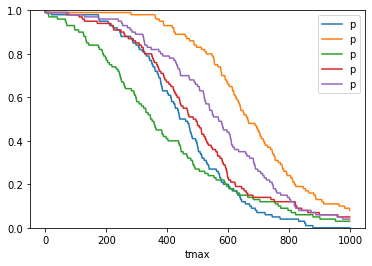

In [ ]:
for r in range(5):
  output = fakeSpread(N)
  ax = plt.gca()

  output.plot(kind='line',x='tmax',y='p',ax=ax)
  plt.ylim(0, 1)

### **Comparing sensitivity of two agents**

In [ ]:
def fakeSpread(N):
  agents = []
  for i in range(N):
    education = (0.2, 0.5, 0.8)
    p = (0.3, 0.4, 0.3)
    e = np.random.choice(education, size=1, p=p)
    agents.append(['A', e[0]])
  #e is the sensitivity to news: low e means you will highly believe the news

  df = pd.DataFrame(agents)

  data = [[1, df[0].value_counts()['A']/N]]
  output = pd.DataFrame(data, columns = ['tmax', 'p'])
  #output

  #Choose a random agent to give him fake news
  i = np.random.choice(range(N))
  agents[i][0] = 'F'


  for t in range(1000):
    j = np.random.choice(range(N))
    k = np.random.choice(range(N))

    if j != k:
      if agents[j][0] != agents[k][0]:
        if agents[j][0] == 'F':
          if agents[j][1] >= agents[k][1]:
            agents[k][0] = 'F'
        elif agents[k][0] == 'F':
          if agents[k][1] >= agents[j][1]:
            agents[j][0] = 'F'
      df = pd.DataFrame(agents)
      exists = 'A' in df[0].unique()
      if exists:
        s = df[0].value_counts()['A']
      else:
        s = 0
      o = {'tmax': t, 'p': s/N}
      output = output.append(o, ignore_index = True)
  return output;

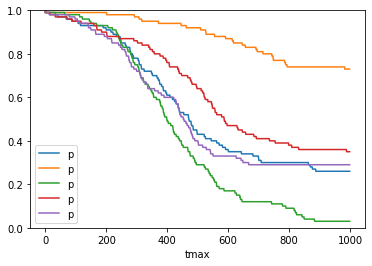

In [ ]:
for r in range(5):
  output = fakeSpread1(N)
  ax = plt.gca()

  output.plot(kind='line',x='tmax',y='p',ax=ax)
  plt.ylim(0, 1)

### **Taking the low sensitivy ( higher e value ) news**

In [ ]:
def fakeSpread2_1(N):
  agents = []
  for i in range(N):
    education = (0.2, 0.5, 0.8)
    p = (0.3, 0.4, 0.3)
    e = np.random.choice(education, size=1, p=p)
    agents.append(['A', e[0]])
  #e is the sensitivity to news: low e means you will highly believe the news

  df = pd.DataFrame(agents)

  data = [[1, df[0].value_counts()['A']/N]]
  output = pd.DataFrame(data, columns = ['tmax', 'p'])
  #output

  #Choose a random agent to give him fake news
  for i in range(10):
      f = np.random.choice(range(N))
      agents[f][0] = 'F'


  for t in range(1000):
    j = np.random.choice(range(N))
    k = np.random.choice(range(N))
    if j != k:
        if agents[j][0] != agents[k][0]:
            if agents[j][1] >= agents[k][1]:
              agents[k][0] = agents[j][0]
            else:
              agents[j][0] = agents[k][0]
    df = pd.DataFrame(agents)
    exists = 'A' in df[0].unique()
    if exists:
      s = df[0].value_counts()['A']
    else:
      s = 0
    o = {'tmax': t, 'p': s/N}
    output = output.append(o, ignore_index = True)
  return output;


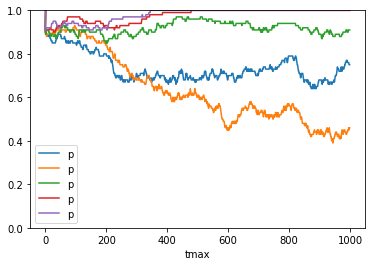

In [ ]:
for r in range(5):
  output = fakeSpread2_1(N)
  ax = plt.gca()

  output.plot(kind='line',x='tmax',y='p',ax=ax)
  plt.ylim(0, 1)

In [ ]:
def fakeSpread2(N):
  agents = []
  for i in range(N):
    education = (0.2, 0.5, 0.8)
    p = (0.3, 0.4, 0.3)
    e = np.random.choice(education, size=1, p=p)
    agents.append(['A', e[0]])
  #e is the sensitivity to news: low e means you will highly believe the news

  df = pd.DataFrame(agents)

  data = [[1, df[0].value_counts()['A']/N]]
  output = pd.DataFrame(data, columns = ['tmax', 'p'])
  #output

  #Choose a random agent to give him fake news
  i = np.random.choice(range(N))
  agents[i][0] = 'F'


  for t in range(1000):
    j = np.random.choice(range(N))
    k = np.random.choice(range(N))
    if t < 500:
      if j != k:
        if agents[j][0] != agents[k][0]:
          if agents[j][0] == 'F':
            if agents[j][1] >= agents[k][1]:
              agents[k][0] = 'F'
          elif agents[k][0] == 'F':
            if agents[k][1] >= agents[j][1]:
              agents[j][0] = 'F'
    else:
      if j != k:
        if agents[j][0] != agents[k][0]:
            if agents[j][1] >= agents[k][1]:
              agents[k][0] = agents[j][0]
            else:
              agents[j][0] = agents[k][0]
    df = pd.DataFrame(agents)
    exists = 'A' in df[0].unique()
    if exists:
      s = df[0].value_counts()['A']
    else:
      s = 0
    o = {'tmax': t, 'p': s/N}
    output = output.append(o, ignore_index = True)
  return output;


### **Networks**

In [ ]:
def fakeSpread4(N, F = 1):
  """
  agents is an empty list

  """
  agents = []
  seed(1)
  for i in range(N):
    e = random()
    popu = (1, 2, 3)
    p = (0.3, 0.4, 0.3)
    net = np.random.choice(popu, size=1, p=p)
    agents.append(['A', e, net[0]])
  #e is the sensitivity to news: low e means you will highly believe the news

  #Choose a random agent to give him fake news
  if F < N:
    for i in range(F):
      f = np.random.choice(range(N))
      agents[f][0] = 'F'
  else:
    print("Number of initial agents with fake news should be inferior to the total population")
    return None;

  df = pd.DataFrame(agents)
  data = [[1, df[0].value_counts()['A']/N]]
  output = pd.DataFrame(data, columns = ['tmax', 'p'])
  #output

  #Simulation
  for t in range(1000):
    j = np.random.choice(range(N))
    k = np.random.choice(range(N))
    if j != k:
      #check if one of them has the FN
      if agents[j][0] != agents[k][0]:
        #check if they are from the same population
        if agents[j][2] == agents[k][2]:
          if agents[j][0] == 'F':
            if agents[j][1] >= agents[k][1]:
              agents[k][0] = 'F'
          elif agents[k][0] == 'F':
            if agents[k][1] >= agents[j][1]:
              agents[j][0] = 'F'
        else:
          #case when they are not from the same population
          if agents[j][1] >= agents[k][1]:
            agents[k][0] = agents[j][0]
          else:
            agents[j][0] = agents[k][0]
    df = pd.DataFrame(agents)
    exists = 'A' in df[0].unique()
    if exists:
      s = df[0].value_counts()['A']
    else:
      s = 0
    o = {'tmax': t, 'p': s/N}
    output = output.append(o, ignore_index = True)
  return output;


(0.0, 1.0)

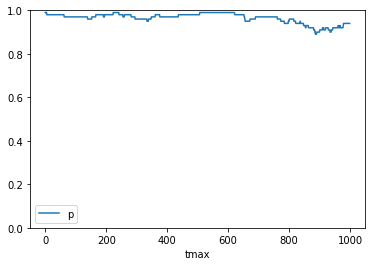

In [ ]:
output = fakeSpread4(N, 1)
ax = plt.gca()

output.plot(kind='line',x='tmax',y='p',ax=ax)
plt.ylim(0, 1)

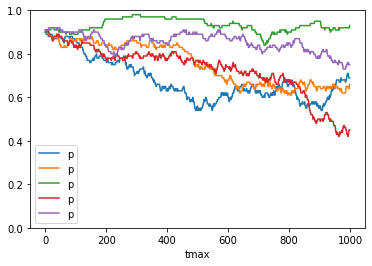

In [ ]:
for r in range(5):
  output = fakeSpread4(N, 10)
  ax = plt.gca()

  output.plot(kind='line',x='tmax',y='p',ax=ax)
  plt.ylim(0, 1)

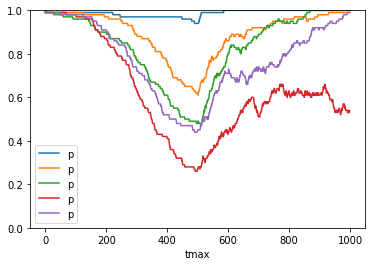

In [ ]:
for r in range(5):
  output = fakeSpread2(N)
  ax = plt.gca()

  output.plot(kind='line',x='tmax',y='p',ax=ax)
  plt.ylim(0, 1)

### **Netrworks A.1**

In [ ]:
def fakeSpread4_1(N, F = 1):
  """
  agents is an empty list

  """
  agents = []
  seed(1)
  for i in range(N):
    e = random()
    popu = (1, 2, 3)
    p = (0.3, 0.4, 0.3)
    net = np.random.choice(popu, size=1, p=p)
    agents.append(['A', e, net[0]])
  #e is the sensitivity to news: low e means you will highly believe the news

  #Choose a random agent to give him fake news
  if F < N:
    for i in range(F):
      f = np.random.choice(range(N))
      agents[f][0] = 'F'
  else:
    print("Number of initial agents with fake news should be inferior to the total population")
    return None;

  df = pd.DataFrame(agents)
  data = [[1, df[0].value_counts()['A']/N]]
  output = pd.DataFrame(data, columns = ['tmax', 'p'])
  #output

  #Simulation
  for t in range(1000):
    j = np.random.choice(range(N))
    k = np.random.choice(range(N))
    if j != k:
      #check if one of them has the FN
      if agents[j][0] != agents[k][0]:
        #check if they are from the same population
        if agents[j][2] == agents[k][2]:
          if agents[j][0] == 'F':
            if agents[j][1] >= agents[k][1]:
              agents[k][0] = 'F'
          elif agents[k][0] == 'F':
            if agents[k][1] >= agents[j][1]:
              agents[j][0] = 'F'
        else:
          #case when they are not from the same population
          if agents[j][1] >= agents[k][1]:
            agents[k][0] = agents[j][0]
          else:
            agents[j][0] = agents[k][0]
    df = pd.DataFrame(agents)
    exists = 'A' in df[0].unique()
    if exists:
      s = df[0].value_counts()['A']
    else:
      s = 0
    o = {'tmax': t, 'p': s/N}
    output = output.append(o, ignore_index = True)
  return output;
